In [6]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

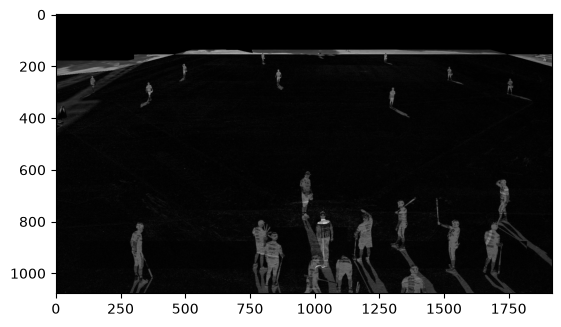

In [8]:
img_bgr = cv.imread('img/kopla.png')
img_test = cv.imread('img/kopla_pelikuva.png')

diff = cv.absdiff(img_bgr, img_test)

img_gray = cv.cvtColor(diff, cv.COLOR_BGR2GRAY)
plt.imshow(img_gray, cmap='gray')
plt.show()

In [ ]:
"""
Player detection pipeline for stationary-camera field footage.

Pipeline stages:
  1. RollingBackgroundModel   - per-pixel median over a sliding window of sampled
                                 frames, refreshed periodically so slow-moving shadows
                                 (sun angle, trees, stands) get absorbed automatically.
  2. ForegroundDetector       - HSV difference + chromaticity-based shadow suppression.
                                 Thresholds below were derived from real pixel samples
                                 taken from your empty_field.png / game_frame_*.png:
                                   clay (ref):   H ~ 8-10,  S ~ 90-100, V ~ 155-185
                                   player kit:   H shifts +5 to +45,   V drops 40-90
                                 i.e. shadow keeps hue/sat close to background and only
                                 drops V moderately; a real player deviates in hue too.
  3. PerspectiveSizeFilter    - rejects/accepts blobs based on expected player pixel
                                 height at that image row, using YOUR calibration.
  4. BlobExtractor            - connected components -> bounding boxes.
  5. CentroidTracker          - greedy nearest-neighbor association across frames +
                                 linear interpolation to fill short gaps.

You already have camera calibration -- plug your real world<->pixel mapping into
PerspectiveSizeFilter.expected_height_px() instead of the placeholder linear
interpolation (built from your two known points: 35px far / 185px near) so this
step is only a temporary stand-in.
"""

import cv2
import numpy as np
from collections import deque, defaultdict


# ----------------------------------------------------------------------------
# 1. Rolling background model
# ----------------------------------------------------------------------------
class RollingBackgroundModel:
    """
    Maintains a per-pixel median background computed from a rolling buffer of
    sparsely-sampled frames. Because this is offline, sampling ~1 frame/sec over
    a multi-minute window and taking the median is enough to "see through" players
    (who rarely occupy the same pixel for the whole window) while still tracking
    slow lighting/shadow changes across the match.
    """

    def __init__(self, initial_bg, max_frames=180):
        # initial_bg: HxWx3 uint8, e.g. your empty_field.png (BGR, alpha stripped)
        self.buffer = deque(maxlen=max_frames)
        self.buffer.append(initial_bg.astype(np.uint8))
        self.current_bg = initial_bg.astype(np.uint8)

    def add_sample(self, frame):
        """Call this ~once per second of video (not every detection frame)."""
        self.buffer.append(frame.astype(np.uint8))

    def recompute(self):
        """Call every N minutes (e.g. every 60-120s of video) to refresh the model."""
        stack = np.stack(self.buffer, axis=0)  # (N, H, W, 3)
        self.current_bg = np.median(stack, axis=0).astype(np.uint8)
        return self.current_bg

    def get(self):
        return self.current_bg


# ----------------------------------------------------------------------------
# 2. Foreground + shadow-aware detector
# ----------------------------------------------------------------------------
class ForegroundDetector:
    def __init__(
        self,
        hue_shadow_tol=6,        # shadow hue stays within this of background hue
        sat_shadow_tol=25,       # shadow saturation stays within this of background
        v_ratio_low=0.35,        # shadow darkens V by at most this much (ratio)
        v_ratio_high=0.95,
        min_abs_diff=18,         # ignore near-zero noise
    ):
        self.hue_tol = hue_shadow_tol
        self.sat_tol = sat_shadow_tol
        self.v_lo = v_ratio_low
        self.v_hi = v_ratio_high
        self.min_abs_diff = min_abs_diff

    def detect(self, frame_bgr, bg_bgr, valid_mask):
        """
        frame_bgr, bg_bgr: HxWx3 uint8
        valid_mask: HxW bool (from your alpha channel, e.g. alpha > 200)
        Returns: HxW uint8 mask (255 = foreground / player candidate)
        """
        f_hsv = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2HSV).astype(np.int16)
        b_hsv = cv2.cvtColor(bg_bgr, cv2.COLOR_BGR2HSV).astype(np.int16)

        h_diff = np.abs(f_hsv[..., 0].astype(int) - b_hsv[..., 0].astype(int))
        h_diff = np.minimum(h_diff, 180 - h_diff)  # hue wraps at 180 in OpenCV
        s_diff = np.abs(f_hsv[..., 1] - b_hsv[..., 1])

        v_f = f_hsv[..., 2].astype(np.float32)
        v_b = np.maximum(b_hsv[..., 2].astype(np.float32), 1.0)
        v_ratio = v_f / v_b

        abs_diff = (np.abs(f_hsv - b_hsv)).sum(axis=2)

        is_shadow = (
            (h_diff <= self.hue_tol)
            & (s_diff <= self.sat_tol)
            & (v_ratio >= self.v_lo)
            & (v_ratio <= self.v_hi)
        )

        is_changed = abs_diff > self.min_abs_diff

        foreground = is_changed & (~is_shadow) & valid_mask
        return (foreground.astype(np.uint8)) * 255


# ----------------------------------------------------------------------------
# 3. Perspective-aware size filter (placeholder -- replace with your calibration)
# ----------------------------------------------------------------------------
class PerspectiveSizeFilter:
    """
    Rejects blobs whose height is implausible for their row in the image.
    Replace expected_height_px() with a lookup through your real camera
    calibration (pixel -> world -> back to expected player height in pixels).
    The two-point linear version here is only a rough stand-in using the
    numbers you gave: 35px tall at the far end, 185px tall at the near end.
    """

    def __init__(self, y_far, h_far, y_near, h_near, tolerance=0.5):
        self.y_far, self.h_far = y_far, h_far
        self.y_near, self.h_near = y_near, h_near
        self.tolerance = tolerance  # allowed fractional deviation from expected

    def expected_height_px(self, y):
        # TODO: replace with your calibration's world-height -> pixel-height mapping
        y = np.clip(y, self.y_far, self.y_near)
        t = (y - self.y_far) / max(self.y_near - self.y_far, 1e-6)
        return self.h_far + t * (self.h_near - self.h_far)

    def is_plausible(self, bbox):
        x, y, w, h = bbox
        cy = y + h  # use bottom of bbox (feet) as the reference row
        expected = self.expected_height_px(cy)
        lo, hi = expected * (1 - self.tolerance), expected * (1 + self.tolerance * 1.8)
        return lo <= h <= hi


# ----------------------------------------------------------------------------
# 4. Blob extraction
# ----------------------------------------------------------------------------
def extract_blobs(mask, min_area=15):
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((5, 9), np.uint8))
    num, labels, stats, centroids = cv2.connectedComponentsWithStats(mask, connectivity=8)
    boxes = []
    for i in range(1, num):
        x, y, w, h, area = stats[i]
        if area < min_area:
            continue
        boxes.append((x, y, w, h))
    return boxes


def detect_players(frame_bgr, bg_bgr, valid_mask, fg_detector, size_filter, min_area=15):
    mask = fg_detector.detect(frame_bgr, bg_bgr, valid_mask)
    boxes = extract_blobs(mask, min_area=min_area)
    boxes = [b for b in boxes if size_filter.is_plausible(b)]
    return boxes, mask


# ----------------------------------------------------------------------------
# 5. Simple centroid tracker with linear gap-filling
# ----------------------------------------------------------------------------
class CentroidTracker:
    def __init__(self, max_dist=60, max_missed=10):
        self.next_id = 0
        self.tracks = {}       # id -> {"centroid": (x,y), "missed": int, "history": {frame_idx: bbox}}
        self.max_dist = max_dist
        self.max_missed = max_missed

    def update(self, frame_idx, boxes):
        centroids = [(x + w / 2, y + h / 2) for (x, y, w, h) in boxes]
        unmatched_tracks = set(self.tracks.keys())
        unmatched_boxes = set(range(len(boxes)))

        # greedy nearest-neighbor matching
        pairs = []
        for tid in list(self.tracks.keys()):
            tc = self.tracks[tid]["centroid"]
            for bi, c in enumerate(centroids):
                d = np.hypot(tc[0] - c[0], tc[1] - c[1])
                if d <= self.max_dist:
                    pairs.append((d, tid, bi))
        pairs.sort(key=lambda p: p[0])

        for d, tid, bi in pairs:
            if tid in unmatched_tracks and bi in unmatched_boxes:
                self.tracks[tid]["centroid"] = centroids[bi]
                self.tracks[tid]["missed"] = 0
                self.tracks[tid]["history"][frame_idx] = boxes[bi]
                unmatched_tracks.discard(tid)
                unmatched_boxes.discard(bi)

        for tid in unmatched_tracks:
            self.tracks[tid]["missed"] += 1

        for bi in unmatched_boxes:
            tid = self.next_id
            self.next_id += 1
            self.tracks[tid] = {
                "centroid": centroids[bi],
                "missed": 0,
                "history": {frame_idx: boxes[bi]},
            }

        # drop stale tracks
        for tid in list(self.tracks.keys()):
            if self.tracks[tid]["missed"] > self.max_missed:
                del self.tracks[tid]

    def interpolated_tracks(self):
        """
        Returns {track_id: {frame_idx: bbox}} with short gaps linearly interpolated.
        Run this once at the end of processing, per track.
        """
        result = {}
        for tid, t in self.tracks.items():
            hist = t["history"]
            frames = sorted(hist.keys())
            if len(frames) < 2:
                result[tid] = dict(hist)
                continue
            filled = dict(hist)
            for a, b in zip(frames[:-1], frames[1:]):
                gap = b - a
                if gap <= 1:
                    continue
                xa, ya, wa, ha = hist[a]
                xb, yb, wb, hb = hist[b]
                for k in range(1, gap):
                    t_frac = k / gap
                    filled[a + k] = (
                        xa + (xb - xa) * t_frac,
                        ya + (yb - ya) * t_frac,
                        wa + (wb - wa) * t_frac,
                        ha + (hb - ha) * t_frac,
                    )
            result[tid] = filled
        return result


# ----------------------------------------------------------------------------
# Example usage skeleton
# ----------------------------------------------------------------------------


In [10]:
ref = cv2.imread("empty_field.png", cv2.IMREAD_UNCHANGED)
valid_mask = ref[:, :, 3] > 200
bg_model = RollingBackgroundModel(ref[:, :, :3])

fg_detector = ForegroundDetector()
# Replace these 4 numbers with real values from your calibration setup
size_filter = PerspectiveSizeFilter(y_far=200, h_far=35, y_near=1000, h_near=185)

tracker = CentroidTracker(max_dist=70, max_missed=8)

cap = cv2.VideoCapture("game.mp4")
fps = cap.get(cv2.CAP_PROP_FPS)
detect_every_n = max(int(round(fps / 8)), 1)   # ~8 fps detection
bg_sample_every_n = int(round(fps))             # 1 fps background sampling
bg_recompute_every = int(round(fps * 90))        # refresh bg every ~90s

frame_idx = 0
while True:
    ret, frame = cap.read()
    if not ret:
        break

    if frame_idx % bg_sample_every_n == 0:
        bg_model.add_sample(frame)
    if frame_idx % bg_recompute_every == 0:
        bg_model.recompute()

    if frame_idx % detect_every_n == 0:
        boxes, mask = detect_players(
            frame, bg_model.get(), valid_mask, fg_detector, size_filter
        )
        tracker.update(frame_idx, boxes)

    frame_idx += 1

cap.release()
all_tracks = tracker.interpolated_tracks()
# all_tracks[id] = {frame_idx: (x, y, w, h), ...} ready for your calibration
# to convert bbox -> world position.